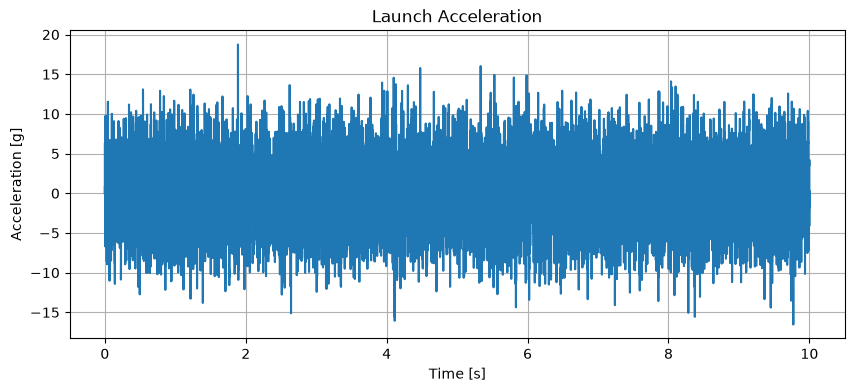

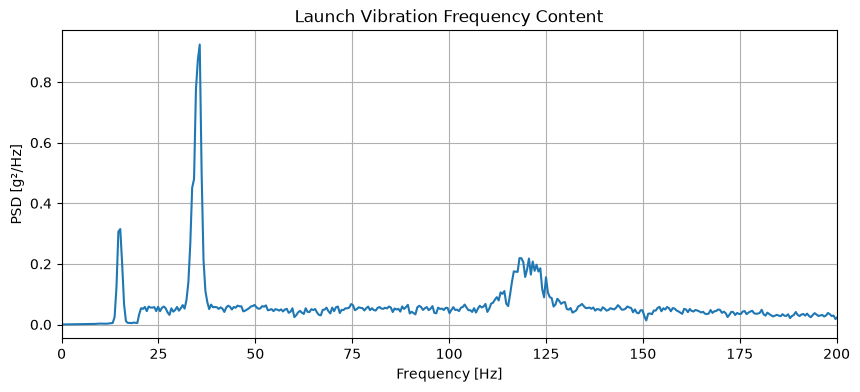

Dominant Frequencies:
35.64 Hz | PSD = 0.9241 g²/Hz
15.14 Hz | PSD = 0.3151 g²/Hz
118.16 Hz | PSD = 0.2191 g²/Hz
120.61 Hz | PSD = 0.2176 g²/Hz
125.00 Hz | PSD = 0.1560 g²/Hz


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
import time

# Load launch data
data = pd.read_csv("launch_vibration.csv")

t = data["time [s]"].to_numpy()
a = data["acceleration [g]"].to_numpy()

# Sampling frequency
fs = 1 / (t[1] - t[0])

# Frequency analysis
freq, psd = welch(a, fs=fs, nperseg=8192)

# Plot acceleration versus time
plt.figure(figsize=(10, 4))
plt.plot(t, a)
plt.xlabel("Time [s]")
plt.ylabel("Acceleration [g]")
plt.title("Launch Acceleration")
plt.grid(True)
plt.show()

# Plot frequency content
plt.figure(figsize=(10, 4))
plt.plot(freq, psd)
plt.xlim(0, 200)
plt.xlabel("Frequency [Hz]")
plt.ylabel("PSD [g²/Hz]")
plt.title("Launch Vibration Frequency Content")
plt.grid(True)
plt.show()
from scipy.signal import find_peaks

# Find peaks in the PSD
peaks, properties = find_peaks(psd, prominence=0.05)

# Sort peaks by PSD magnitude (largest first)
peaks = peaks[np.argsort(psd[peaks])[::-1]]

print("Dominant Frequencies:")
for p in peaks:
    print(f"{freq[p]:.2f} Hz | PSD = {psd[p]:.4f} g²/Hz")


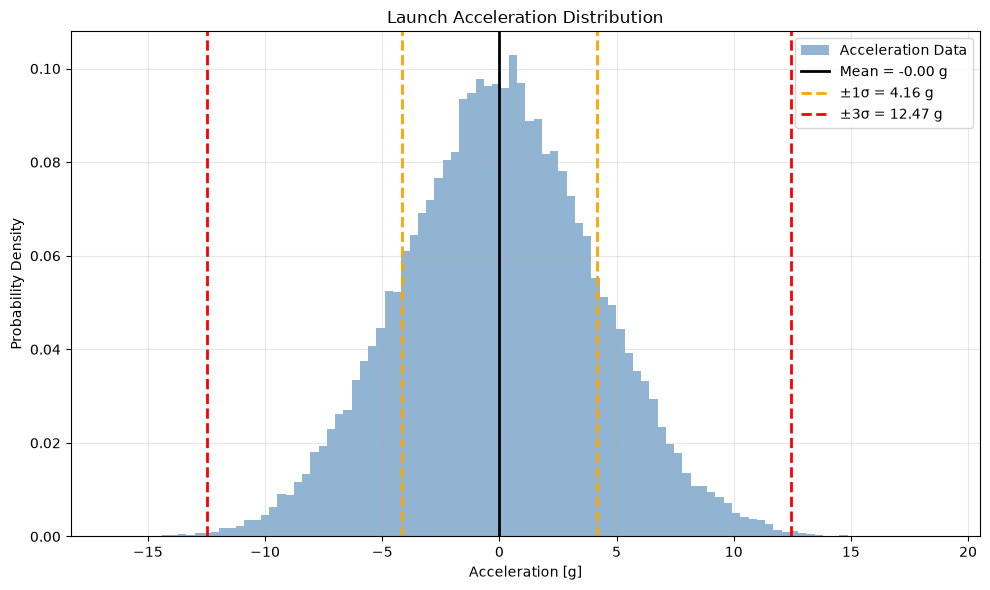

In [ ]:
# Calculate acceleration statistics
mean_accel = np.mean(a)
sigma = np.std(a)
three_sigma = 3 * sigma

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(a, bins=100, density=True, alpha=0.6,
         color="steelblue", edgecolor="none",
         label="Acceleration Data")

# Mean
plt.axvline(mean_accel, color="black", linestyle="-",
            linewidth=2, label=f"Mean = {mean_accel:.2f} g")

# +/- 1 sigma
plt.axvline(mean_accel + sigma, color="orange", linestyle="--",
            linewidth=2, label=f"±1σ = {sigma:.2f} g")
plt.axvline(mean_accel - sigma, color="orange", linestyle="--",
            linewidth=2)

# +/- 3 sigma
plt.axvline(mean_accel + three_sigma, color="red", linestyle="--",
            linewidth=2, label=f"±3σ = {three_sigma:.2f} g")
plt.axvline(mean_accel - three_sigma, color="red", linestyle="--",
            linewidth=2)

plt.xlabel("Acceleration [g]")
plt.ylabel("Probability Density")
plt.title("Launch Acceleration Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


========== ACCELERATION RESULTS ==========
Original mean: -0.0000 g
Damped mean:   -0.0000 g

Original 1-sigma: 4.1552 g
Damped 1-sigma:   3.9671 g

Original 3-sigma: 12.4657 g
Damped 3-sigma:   11.9014 g

3-sigma reduction: 4.53%
Meets 20% target: False

========== OPTIMIZED DAMPER 1 ==========
Mass: 20.0000 kg
Natural frequency: 33.87 Hz
Damping ratio: 0.0823
Stiffness: 906039.96 N/m
Damping coefficient: 700.90 Ns/m

========== OPTIMIZED DAMPER 2 ==========
Mass: 20.0000 kg
Natural frequency: 39.61 Hz
Damping ratio: 0.4000
Stiffness: 1238825.76 N/m
Damping coefficient: 3982.08 Ns/m

Total damper mass: 40.0000 kg


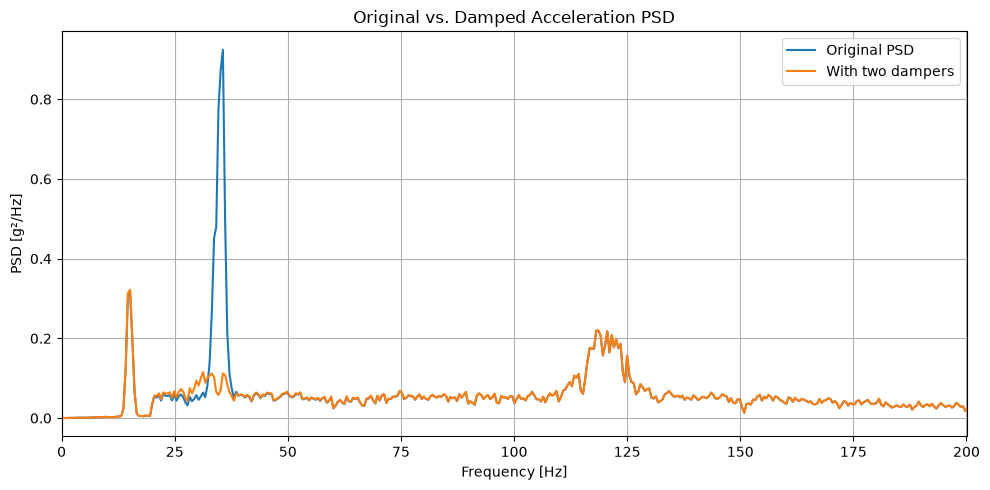

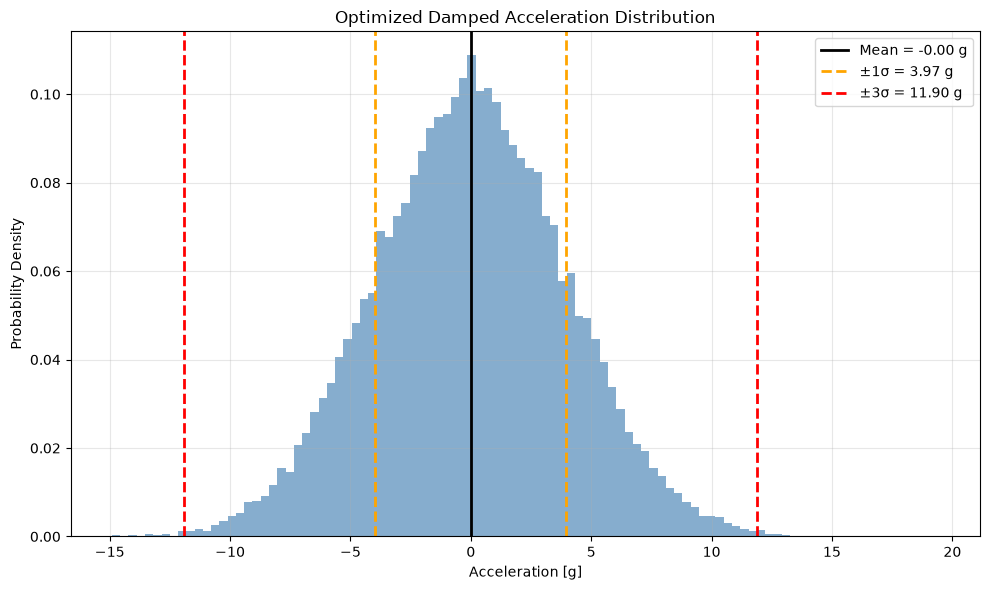

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.optimize import differential_evolution


# ============================================================
# LOAD ACCELERATION DATA
# ============================================================

df = pd.read_csv("launch_vibration.csv")

t = df["time [s]"].to_numpy()
a = df["acceleration [g]"].to_numpy()

fs = 1 / np.mean(np.diff(t))


# ============================================================
# SATELLITE PROPERTIES
# ============================================================

m1 = 1000          # Satellite mass [kg]
fn1 = 35           # Assumed natural frequency [Hz]
zeta1 = 0.02       # Assumed damping ratio

w1 = 2 * np.pi * fn1
k1 = m1 * w1**2
c1 = 2 * zeta1 * m1 * w1


# ============================================================
# ORIGINAL SATELLITE RESPONSE
# ============================================================

def original_response(w):

    D = k1 - m1*w**2 + 1j*w*c1

    return 1 / D


# ============================================================
# SATELLITE RESPONSE WITH TWO DAMPERS
# ============================================================

def damped_response(w, m2, m3, f2, f3, zeta2, zeta3):

    w2 = 2 * np.pi * f2
    w3 = 2 * np.pi * f3

    k2 = m2 * w2**2
    k3 = m3 * w3**2

    c2 = 2 * zeta2 * m2 * w2
    c3 = 2 * zeta3 * m3 * w3

    Z2 = k2 + 1j*w*c2
    Z3 = k3 + 1j*w*c3

    D1 = k1 - m1*w**2 + 1j*w*c1

    # Dynamic stiffness contributions of the dampers
    term2 = np.zeros_like(D1, dtype=complex)
    term3 = np.zeros_like(D1, dtype=complex)

    if m2 > 0:
        term2 = Z2**2 / (Z2 - m2*w**2)

    if m3 > 0:
        term3 = Z3**2 / (Z3 - m3*w**2)

    D_new = D1 + Z2 + Z3 - term2 - term3

    return 1 / D_new


# ============================================================
# ORIGINAL ACCELERATION FFT
# ============================================================

mean_original = np.mean(a)
sigma_original = np.std(a)

# Remove mean before FFT
A_original = np.fft.rfft(a - mean_original)

fft_freq = np.fft.rfftfreq(len(a), d=1/fs)
w_fft = 2 * np.pi * fft_freq

H_original_fft = original_response(w_fft)


# ============================================================
# RECONSTRUCT DAMPED ACCELERATION
# ============================================================

def reconstruct_acceleration(params):

    m2, m3, f2, f3, zeta2, zeta3 = params

    H_damped_fft = damped_response(
        w_fft, m2, m3, f2, f3, zeta2, zeta3
    )

    # Ratio of damped and original responses
    ratio = H_damped_fft / H_original_fft

    # Apply ratio to measured acceleration FFT
    A_damped = A_original * ratio

    # Convert back to time domain
    a_damped = np.fft.irfft(A_damped, n=len(a))

    # Restore original mean
    a_damped += mean_original

    return a_damped


# ============================================================
# OPTIMIZATION: MINIMIZE 3-SIGMA ACCELERATION
# ============================================================

def objective(params):

    a_damped = reconstruct_acceleration(params)

    return 3 * np.std(a_damped)


bounds = [
    (0.1, 20),      # Damper 1 mass [kg]
    (0.1, 20),      # Damper 2 mass [kg]
    (25, 45),       # Damper 1 frequency [Hz]
    (25, 45),       # Damper 2 frequency [Hz]
    (0.01, 0.40),   # Damper 1 damping ratio
    (0.01, 0.40)    # Damper 2 damping ratio
]

result = differential_evolution(
    objective,
    bounds,
    seed=42,
    maxiter=150,
    tol=1e-5
)


# ============================================================
# OPTIMIZED DAMPER PARAMETERS
# ============================================================

m2, m3, f2, f3, zeta2, zeta3 = result.x

w2 = 2 * np.pi * f2
w3 = 2 * np.pi * f3

k2 = m2 * w2**2
k3 = m3 * w3**2

c2 = 2 * zeta2 * m2 * w2
c3 = 2 * zeta3 * m3 * w3

# Reconstruct optimized acceleration
a_damped = reconstruct_acceleration(result.x)


# ============================================================
# ACCELERATION STATISTICS
# ============================================================

mean_damped = np.mean(a_damped)
sigma_damped = np.std(a_damped)

three_sigma_original = 3 * sigma_original
three_sigma_damped = 3 * sigma_damped

reduction = 100 * (
    1 - three_sigma_damped / three_sigma_original
)

print("\n========== ACCELERATION RESULTS ==========")

print(f"Original mean: {mean_original:.4f} g")
print(f"Damped mean:   {mean_damped:.4f} g")

print(f"\nOriginal 1-sigma: {sigma_original:.4f} g")
print(f"Damped 1-sigma:   {sigma_damped:.4f} g")

print(f"\nOriginal 3-sigma: {three_sigma_original:.4f} g")
print(f"Damped 3-sigma:   {three_sigma_damped:.4f} g")

print(f"\n3-sigma reduction: {reduction:.2f}%")
print(f"Meets 20% target: {reduction >= 20}")

print("\n========== OPTIMIZED DAMPER 1 ==========")

print(f"Mass: {m2:.4f} kg")
print(f"Natural frequency: {f2:.2f} Hz")
print(f"Damping ratio: {zeta2:.4f}")
print(f"Stiffness: {k2:.2f} N/m")
print(f"Damping coefficient: {c2:.2f} Ns/m")

print("\n========== OPTIMIZED DAMPER 2 ==========")

print(f"Mass: {m3:.4f} kg")
print(f"Natural frequency: {f3:.2f} Hz")
print(f"Damping ratio: {zeta3:.4f}")
print(f"Stiffness: {k3:.2f} N/m")
print(f"Damping coefficient: {c3:.2f} Ns/m")

print(f"\nTotal damper mass: {m2 + m3:.4f} kg")


# ============================================================
# PSD COMPARISON
# ============================================================

freq, psd = welch(a, fs=fs, nperseg=8192)

freq_damped, psd_damped = welch(
    a_damped, fs=fs, nperseg=8192
)

plt.figure(figsize=(10, 5))

plt.plot(freq, psd, label="Original PSD")
plt.plot(freq_damped, psd_damped, label="With two dampers")

plt.xlim(0, 200)
plt.xlabel("Frequency [Hz]")
plt.ylabel("PSD [g²/Hz]")
plt.title("Original vs. Damped Acceleration PSD")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# DAMPED ACCELERATION HISTOGRAM
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    a_damped,
    bins=100,
    density=True,
    color="steelblue",
    alpha=0.65
)

# Mean
plt.axvline(
    mean_damped,
    color="black",
    linewidth=2,
    label=f"Mean = {mean_damped:.2f} g"
)

# +/- 1 sigma
plt.axvline(
    mean_damped + sigma_damped,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"±1σ = {sigma_damped:.2f} g"
)

plt.axvline(
    mean_damped - sigma_damped,
    color="orange",
    linestyle="--",
    linewidth=2
)

# +/- 3 sigma
plt.axvline(
    mean_damped + three_sigma_damped,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"±3σ = {three_sigma_damped:.2f} g"
)

plt.axvline(
    mean_damped - three_sigma_damped,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Acceleration [g]")
plt.ylabel("Probability Density")
plt.title("Optimized Damped Acceleration Distribution")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
